In [53]:

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.datasets import mnist
from keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.regularizers import l1





In [48]:
# 2. Load MNIST Dataset

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [49]:
# 2. Normalize images
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

#  Flatten Images (28 x 28 = 784)
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)


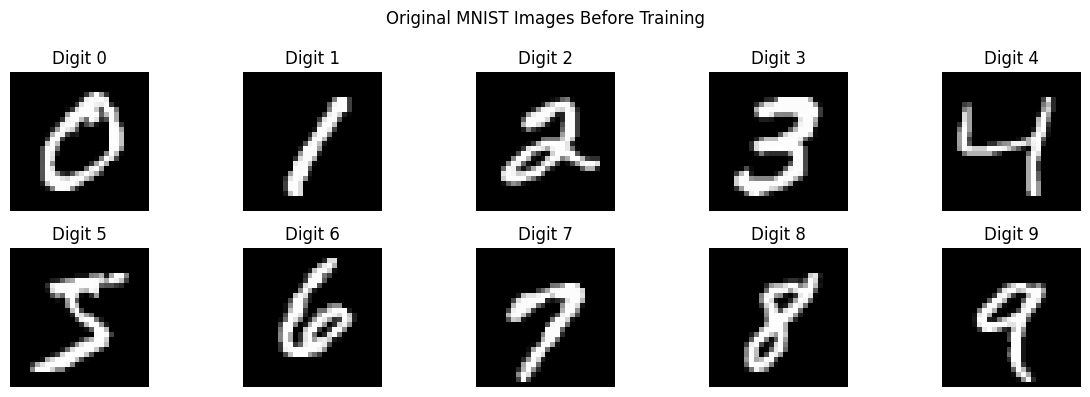

In [51]:
# Select Images from 0 to 9
# 3. Display Original Images (0-9) BEFORE Training

plt.figure(figsize=(12, 4))

for digit in range(10):

    index = np.where(y_train == digit)[0][0]

    plt.subplot(2, 5, digit + 1)

    # Reshape image into 28x28
    plt.imshow(x_train[index].reshape(28, 28), cmap='gray')

    plt.title("Digit " + str(digit))
    plt.axis('off')

plt.suptitle("Original MNIST Images Before Training")
plt.tight_layout()
plt.show()

In [60]:
# 6. Build Sparse Autoencoder

# Encoder
input_img = Input(shape=(784,))

encoded = Dense(
    128,
    activation='relu',
    activity_regularizer=l1(0.00001)
)(input_img)

# Decoder
decoded = Dense(784, activation='sigmoid')(encoded)

# Autoencoder Model
autoencoder = Model(input_img, decoded)

# Compile
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

autoencoder.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 201,616 (787.56 KB)

 Trainable params: 201,616 (787.56 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
# 7. Compile Model
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

autoencoder.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 201,616 (787.56 KB)

 Trainable params: 201,616 (787.56 KB)

 Non-trainable params: 0 (0.00 B)

In [62]:
# 8. Train Model
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5187 - val_loss: 0.2787
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.2601 - val_loss: 0.2246
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2208 - val_loss: 0.2065
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.2045 - val_loss: 0.1945
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1932 - val_loss: 0.1860
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1849 - val_loss: 0.1791
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.1788 - val_loss: 0.1737
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1732 - val_loss: 0.1692
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.1692 - val_loss: 0.1655
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1660 - val_loss: 0.1623


In [63]:
# 9. Reconstruct Images AFTER Training
reconstructed = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


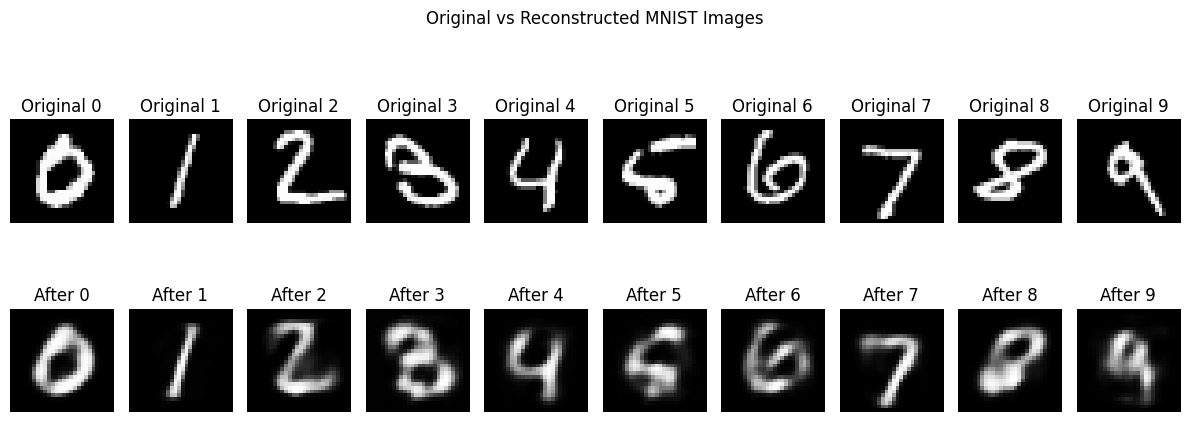

In [64]:
# 10. Display Original and Reconstructed Images
plt.figure(figsize=(12, 5))

for digit in range(10):

    index = np.where(y_test == digit)[0][0]

    # Original Image
    plt.subplot(2, 10, digit + 1)
    plt.imshow(x_test[index].reshape(28, 28), cmap='gray')
    plt.title("Original " + str(digit))
    plt.axis('off')

    # Reconstructed Image
    plt.subplot(2, 10, digit + 11)
    plt.imshow(reconstructed[index].reshape(28, 28), cmap='gray')
    plt.title("After " + str(digit))
    plt.axis('off')

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()
